# 02 – Feature engineering

Phase 4: the feature pipeline is fitted on the training rows only and applied to the validation rows. This notebook re-fits it and checks that it gives exactly the saved features.

In [1]:
# Setup: work from the project root so the project code and configs are found
import os, sys, json, platform, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
from src.utils.config import load_config, resolve_path
REPORTS = resolve_path(load_config("project")["paths"]["reports"])
FIG = resolve_path(load_config("project")["paths"]["figures"])
print("Project folder:", ROOT)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)

Project folder: C:\AL_outcome_predictor
Python 3.12.0 | numpy 2.5.4 | pandas 3.0.6


## 1. Re-fit the pipeline on the training rows

In [2]:
from src.data.split import load_split_rows
from src.features.build import FeaturePipeline
train, validation = load_split_rows("train"), load_split_rows("validation")
pipe = FeaturePipeline(load_config("features")).fit(train)
x_train, x_val = pipe.transform(train), pipe.transform(validation)
print("Training rows:", x_train.shape, "| validation rows:", x_val.shape)

Training rows: (709, 98) | validation rows: (152, 98)


## 2. Same result as the saved features (used for training)

In [3]:
processed = resolve_path(load_config("project")["paths"]["processed"])
for name, fresh in (("train", x_train), ("validation", x_val)):
    saved = pd.read_csv(processed / f"features_{name}.csv")[fresh.columns]
    diff = np.abs(saved.to_numpy(float) - fresh.to_numpy(float)).max()
    print(f"{name}: largest difference from the saved features = {diff:.2e}")

train: largest difference from the saved features = 4.44e-16
validation: largest difference from the saved features = 4.44e-16


## 3. Feature sets compared in Phase 6, and the 34 columns finally used

In [4]:
sets = json.loads((REPORTS / "phase04" / "feature_sets.json").read_text("utf-8"))
print("Feature set sizes:", sets["sizes"])
final = json.loads((REPORTS / "phase06" / "final_columns.json").read_text("utf-8"))
print(len(final), "columns used by the final models:")
pd.DataFrame({"column": final})

Feature set sizes: {'full': 97, 'composites': 85, 'filtered': 34}
34 columns used by the final models:


,column
0,ol_first_language
1,ol_maths
2,ol_history
3,ol_science
4,ol_cat1
5,ol_cat2
6,ol_cat3
7,class_rank_freq
8,g11_self_study_hours
9,career_goal_clear


## 4. How each feature is made (catalogue, first rows)

In [5]:
cat = pd.read_csv(REPORTS / "phase04" / "feature_catalogue.csv")
cat[cat["feature"].isin(final)][["feature", "type", "formula"]].head(15)

,feature,type,formula
1,ol_first_language,ordinal (standardised),"ordinal code, median-imputed, standardised"
3,ol_maths,ordinal (standardised),"ordinal code, median-imputed, standardised"
4,ol_history,ordinal (standardised),"ordinal code, median-imputed, standardised"
5,ol_science,ordinal (standardised),"ordinal code, median-imputed, standardised"
6,ol_cat1,ordinal (standardised),"ordinal code, median-imputed, standardised"
7,ol_cat2,ordinal (standardised),"ordinal code, median-imputed, standardised"
8,ol_cat3,ordinal (standardised),"ordinal code, median-imputed, standardised"
9,class_rank_freq,ordinal (standardised),"ordinal code, median-imputed, standardised"
10,g11_self_study_hours,ordinal (standardised),"ordinal code, median-imputed, standardised"
12,career_goal_clear,ordinal (standardised),"ordinal code, median-imputed, standardised"


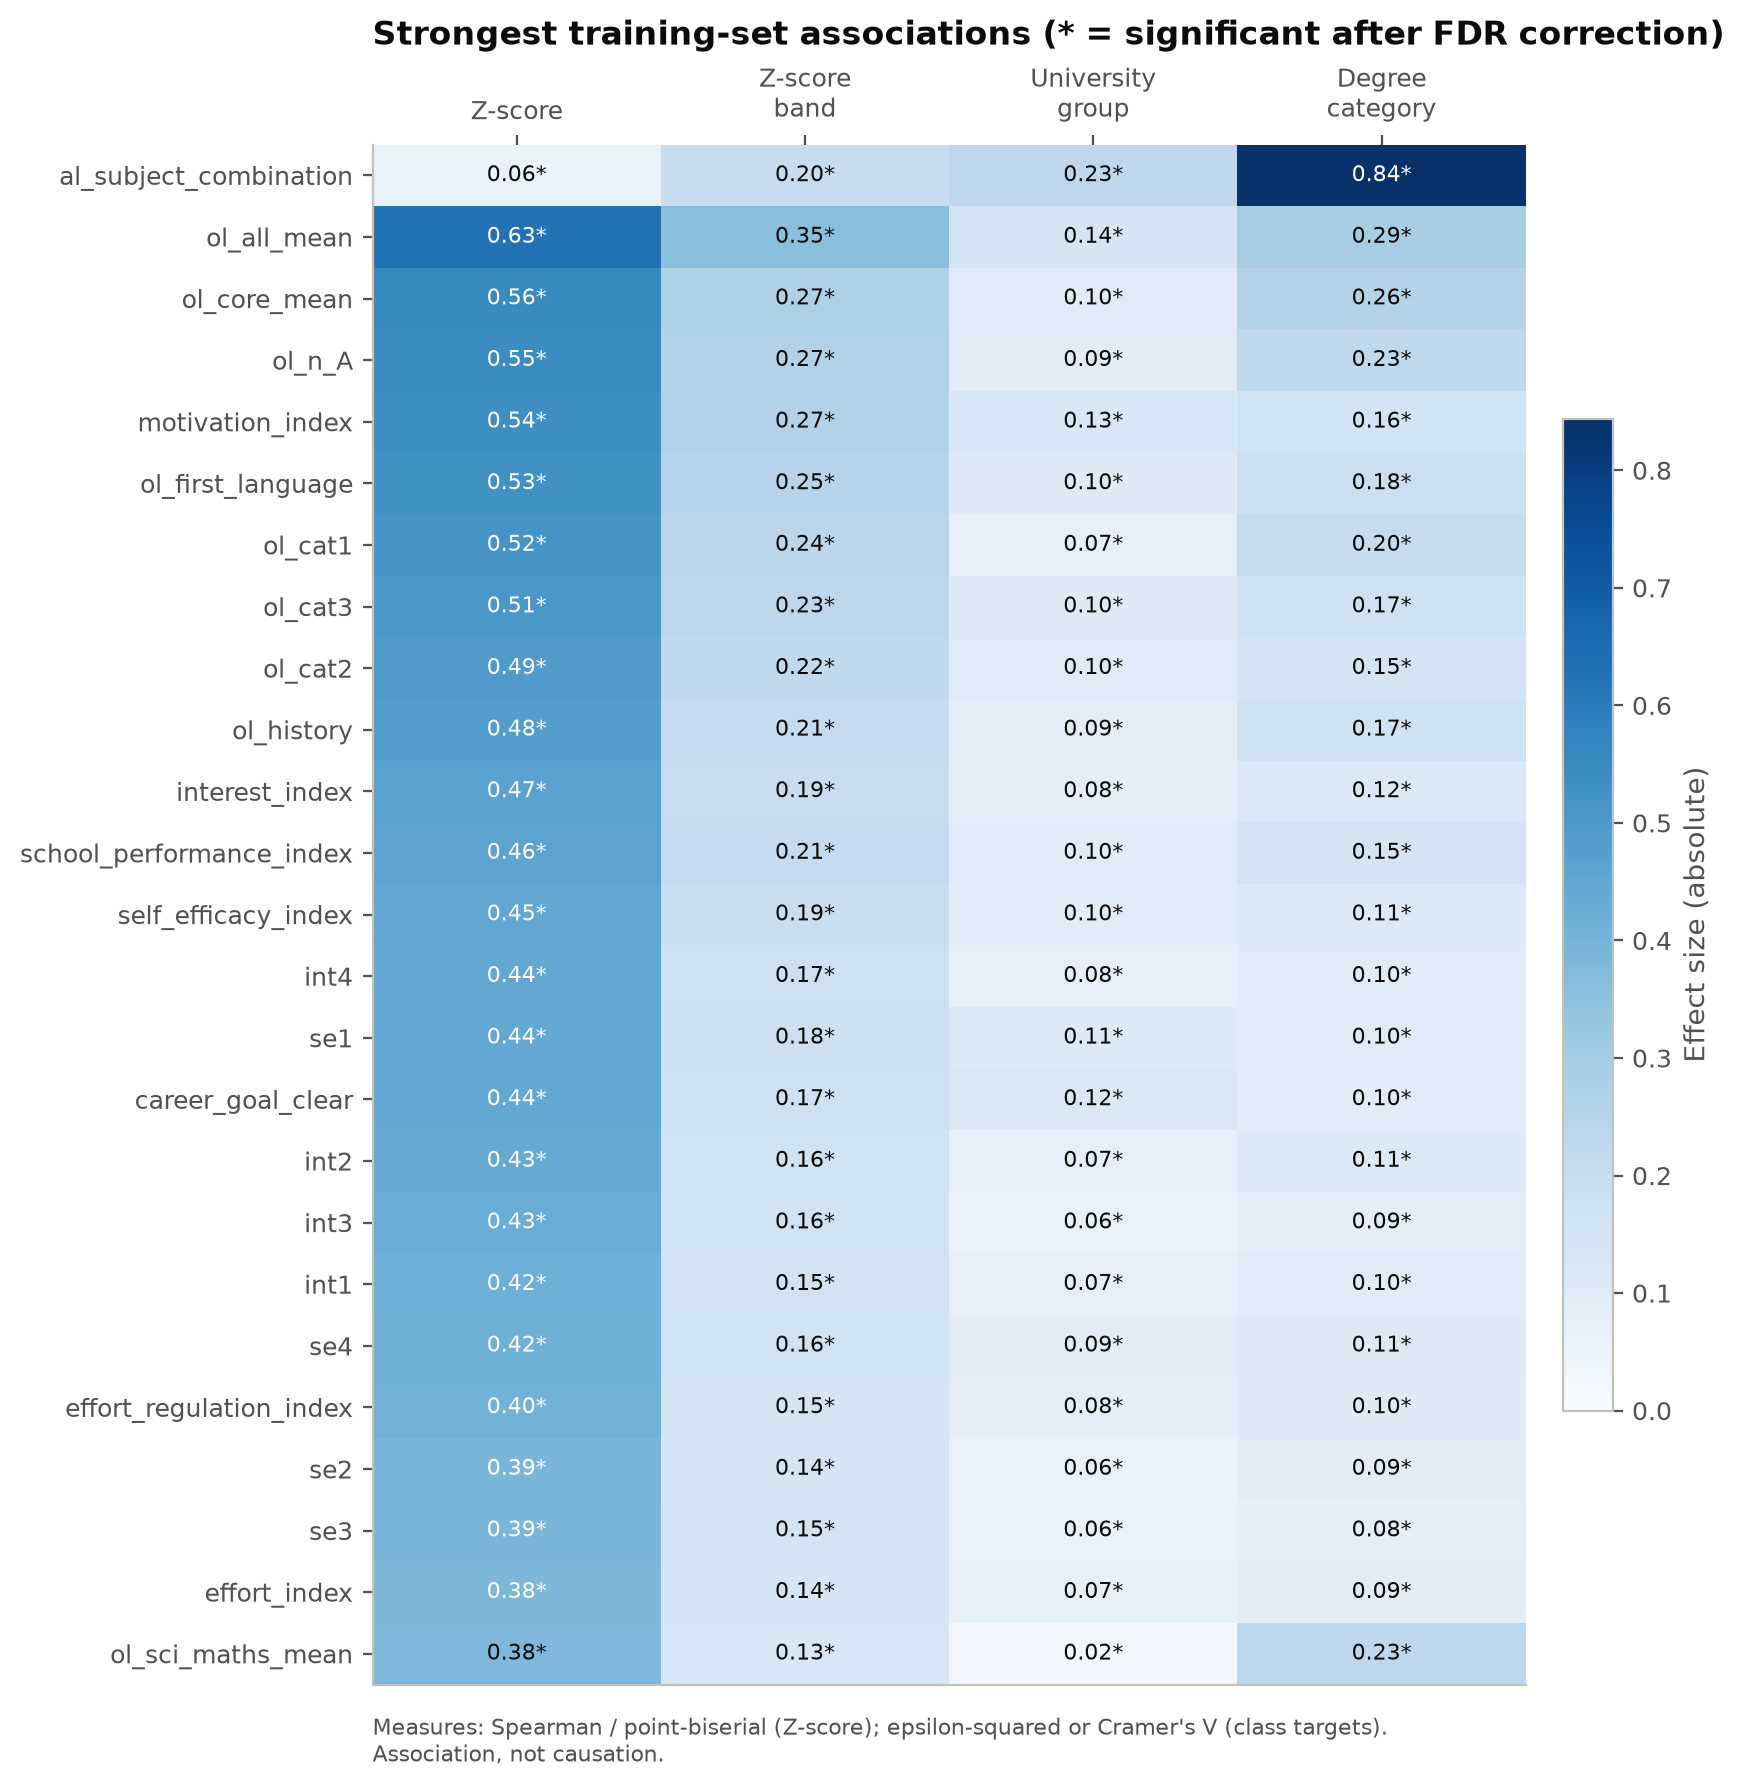

In [6]:
display(Image(str(FIG / "phase04_relevance.png"), width=760))